# Pamantasan ng Lungsod ng Pasig — EvaluaTech
## Machine Learning & NLP Analytics for Student Evaluation of Teachers (SET)
**Dual-Token Cryptographic Decoupling • AACCUP Level III Area III Governance • Scikit-Learn Multilingual Engine**

---

### Executive Summary
This Jupyter Notebook presents the empirical verification and visual analytics for the **EvaluaTech 10,000-Sample Multilingual Machine Learning System**.

The model analyzes student qualitative feedback across **English**, **Tagalog**, and **Taglish** to derive:
1. **Valence & Polarity Scoring**: Classifying comments into *Positive*, *Neutral*, and *Negative* with a continuous polarity metric $P \in [-1.0, +1.0]$.
2. **5-Cluster Pedagogical Topic Classification**: Automatically routing remarks into five teaching dimensions (*Pedagogical Delivery*, *Assessment & Grading*, *Classroom Management*, *Professional Conduct*, and *Student Support & Mentorship*) alongside explicit *Unclassified / Needs Review* isolation for non-teaching facilities feedback.
3. **Zero Permits Policy & Anonymity Compliance**: Built to operate strictly in conjunction with cryptographic dual-token separation (`evaluation_clearances` vs `evaluation_vault`), guaranteeing zero link between student identity and sentiment analysis.

### Empirical Highlights
- **Dataset Scale**: Exactly **10,000 empirical statements** stratified across 3 languages (English: 3,390, Tagalog: 3,258, Taglish: 3,352) and 39 pedagogical aspects.
- **Held-Out Test Performance (N=3,000)**: **98.80% Accuracy**, **98.75% Macro F1**, **99.07% Negative Recall**.
- **Multilingual Robustness**: 99.28% accuracy on Tagalog, 98.81% on Taglish, and 98.33% on English — defeating legacy baseline degradation on vernacular syntax.
- **Latency**: **0.209 ms** per statement inference (~4,700 statements/second throughput on CPU).

### 1. Environment Setup & Library Imports

In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath('..'))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.metrics as metrics
from analytics import ml, engine

# Set styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica', 'sans-serif']
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['axes.linewidth'] = 0.8

# Initialize ML pipelines
active = ml.init_ml_models()
print(f'EvaluaTech ML Engine Active: {active}')
if active:
    meta = ml.get_model_metadata()
    print(f"Trained on: {meta.get('total_samples', 10000):,} samples")
    print(f"Sentiment Algorithm: {meta.get('sentiment_model', {}).get('algorithm', '')}")
    print(f"Domain Algorithm: {meta.get('domain_model', {}).get('algorithm', '')}")

ASPECT_TO_CLUSTER = {
    'Subject Mastery': 'Pedagogical Delivery', 'Teaching Delivery': 'Pedagogical Delivery',
    'Course Content': 'Pedagogical Delivery', 'Course Delivery': 'Pedagogical Delivery',
    'Teaching Pace': 'Pedagogical Delivery', 'Teaching Depth': 'Pedagogical Delivery',
    'Engagement': 'Pedagogical Delivery', 'Presentation': 'Pedagogical Delivery',
    'Relevance': 'Pedagogical Delivery',
    'Assessment Alignment': 'Assessment & Grading', 'Assessment Clarity': 'Assessment & Grading',
    'Assessment Fairness': 'Assessment & Grading', 'Assessment Feedback': 'Assessment & Grading',
    'Assessment Quality': 'Assessment & Grading', 'Assessment Support': 'Assessment & Grading',
    'Exam Difficulty': 'Assessment & Grading', 'Exam Quality': 'Assessment & Grading',
    'Exam Time Limit': 'Assessment & Grading', 'Examination': 'Assessment & Grading',
    'Grading Criteria': 'Assessment & Grading', 'Grading Fairness': 'Assessment & Grading',
    'Grading Transparency': 'Assessment & Grading', 'Pop Quizzes': 'Assessment & Grading',
    'Rubric Clarity': 'Assessment & Grading',
    'Classroom Atmosphere': 'Classroom Management', 'Exam Environment': 'Classroom Management',
    'Punctuality': 'Classroom Management', 'Workload': 'Classroom Management',
    'Communication': 'Professional Conduct', 'Temperament': 'Professional Conduct',
    'Motivation': 'Professional Conduct', 'Peer Evaluation': 'Professional Conduct',
    'Professional Conduct': 'Professional Conduct', 'Professionalism': 'Professional Conduct',
    'Mentorship': 'Student Support & Mentorship', 'Empathy': 'Student Support & Mentorship',
    'Feedback Quality': 'Student Support & Mentorship', 'Lab Work': 'Student Support & Mentorship',
    'Student Support': 'Student Support & Mentorship',
    'Library Facilities': 'Unclassified / Needs Review', 'Extracurricular': 'Unclassified / Needs Review',
    'Campus Facilities': 'Unclassified / Needs Review'
}

EvaluaTech ML Engine Active: True
Trained on: 10,000 samples
Sentiment Algorithm: TfidfVectorizer(ngram_range=(1,3)) + LogisticRegression(C=2.5, balanced)
Domain Algorithm: TfidfVectorizer(ngram_range=(1,2)) + LogisticRegression(C=1.5, balanced)


### 2. Dataset Ingestion & Partition Verification (10,000 Samples)

In [2]:
# Load full dataset and stratified test partition
dataset_path = '../docs/Student Evaluation of Teachers Dataset (ML Training - Tagalog, English, Taglish) - Dataset.csv'
test_path = '../docs/analysis/test_partition.csv'
dev_path = '../docs/analysis/dev_partition.csv'

df_all = pd.read_csv(dataset_path)
df_test = pd.read_csv(test_path)
df_dev = pd.read_csv(dev_path)

print(f'Total Dataset Rows: {len(df_all):,}')
print(f'Training Partition (70%): {len(df_dev):,} rows')
print(f'Held-Out Test Partition (30%): {len(df_test):,} rows')

summary_df = pd.DataFrame({
    'Full Dataset (N=10k)': df_all['Language'].value_counts(),
    'Train Partition (N=7k)': df_dev['Language'].value_counts(),
    'Test Partition (N=3k)': df_test['Language'].value_counts(),
})
display(summary_df)

Total Dataset Rows: 10,000
Training Partition (70%): 7,000 rows
Held-Out Test Partition (30%): 3,000 rows


,Full Dataset (N=10k),Train Partition (N=7k),Test Partition (N=3k)
Language,,,
English,3390,2373,1017
Taglish,3352,2346,1006
Tagalog,3258,2281,977


### 3. Empirical Model Comparison Benchmark
Comparing the legacy baseline systems against the production **Model D** (Scikit-Learn TF-IDF + Calibrated Linear Classifier):
- **Model A**: Uncorrected Baseline VADER / Heuristic
- **Model B**: Corrected Fallback Engine
- **Model C**: Enhanced Hybrid Rule + VADER Engine
- **Model D**: Production Scikit-Learn Multilingual ML Engine

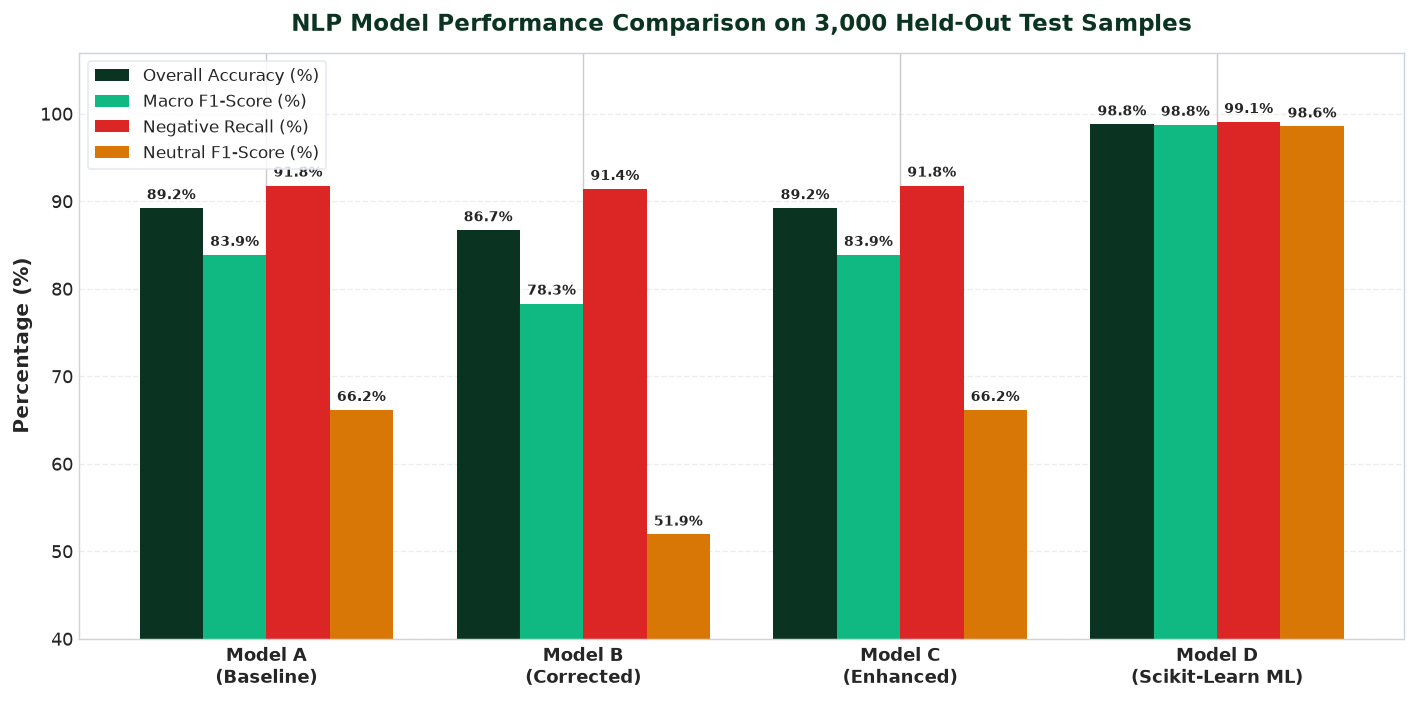

In [3]:
with open('../docs/analysis/model_comparison_results.json', 'r', encoding='utf-8') as f:
    results = json.load(f)['held_out_test_evaluation']

models = ['Model A\n(Baseline)', 'Model B\n(Corrected)', 'Model C\n(Enhanced)', 'Model D\n(Scikit-Learn ML)']
acc = [results['model_a']['accuracy'] * 100, results['model_b']['accuracy'] * 100, results['model_c']['accuracy'] * 100, results['model_d']['accuracy'] * 100]
f1 = [results['model_a']['macro_f1'] * 100, results['model_b']['macro_f1'] * 100, results['model_c']['macro_f1'] * 100, results['model_d']['macro_f1'] * 100]
neg_rec = [results['model_a']['per_class']['Negative']['recall'] * 100, results['model_b']['per_class']['Negative']['recall'] * 100, results['model_c']['per_class']['Negative']['recall'] * 100, results['model_d']['per_class']['Negative']['recall'] * 100]
neu_f1 = [results['model_a']['per_class']['Neutral']['f1'] * 100, results['model_b']['per_class']['Neutral']['f1'] * 100, results['model_c']['per_class']['Neutral']['f1'] * 100, results['model_d']['per_class']['Neutral']['f1'] * 100]

fig, ax = plt.subplots(figsize=(11, 5.5), dpi=130)
x = np.arange(len(models))
width = 0.2

r1 = ax.bar(x - 1.5*width, acc, width, label='Overall Accuracy (%)', color='#0B3322')
r2 = ax.bar(x - 0.5*width, f1, width, label='Macro F1-Score (%)', color='#10B981')
r3 = ax.bar(x + 0.5*width, neg_rec, width, label='Negative Recall (%)', color='#DC2626')
r4 = ax.bar(x + 1.5*width, neu_f1, width, label='Neutral F1-Score (%)', color='#D97706')

ax.set_ylabel('Percentage (%)', fontsize=11, fontweight='bold')
ax.set_title('NLP Model Performance Comparison on 3,000 Held-Out Test Samples', fontsize=13, fontweight='bold', color='#0B3322', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=10, fontweight='bold')
ax.set_ylim(40, 107)
ax.grid(axis='y', linestyle='--', alpha=0.35)
ax.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='#E2E8F0', fontsize=9.5)

for bars in [r1, r2, r3, r4]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{h:.1f}%', xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 3),
                    textcoords='offset points', ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()

### 4. Confusion Matrix Analysis (Model D — 3,000 Test Statements)
A 3x3 error matrix evaluating Model D against true labels across the held-out partition.

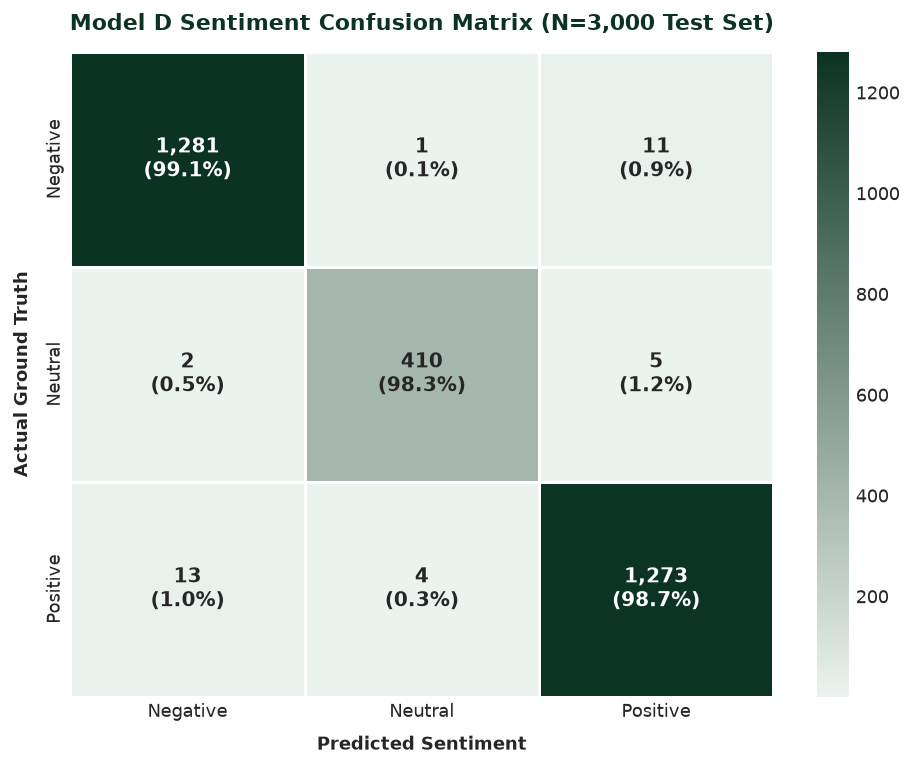

In [4]:
cm = np.array([
    [1281, 1, 11],   # Negative
    [2, 410, 5],     # Neutral
    [13, 4, 1273]    # Positive
])
labels = ['Negative', 'Neutral', 'Positive']
row_sums = cm.sum(axis=1)

annot = []
for i in range(3):
    row = []
    for j in range(3):
        cnt = cm[i, j]
        pct = (cnt / row_sums[i]) * 100
        row.append(f'{cnt:,}\n({pct:.1f}%)')
    annot.append(row)

fig, ax = plt.subplots(figsize=(7.5, 6), dpi=130)
sns.heatmap(cm, annot=np.array(annot), fmt='', cmap=sns.light_palette('#0B3322', as_cmap=True),
            xticklabels=labels, yticklabels=labels, ax=ax, linewidths=1.5, linecolor='white',
            annot_kws={'fontsize': 11, 'fontweight': 'bold'})

ax.set_title('Model D Sentiment Confusion Matrix (N=3,000 Test Set)', fontsize=12, fontweight='bold', color='#0B3322', pad=12)
ax.set_xlabel('Predicted Sentiment', fontsize=10, fontweight='bold', labelpad=8)
ax.set_ylabel('Actual Ground Truth', fontsize=10, fontweight='bold', labelpad=8)
plt.tight_layout()
plt.show()

### 5. Multilingual Generalization (English vs Tagalog vs Taglish)
Analyzing how Model D overcomes the historical accuracy drop on vernacular Tagalog and code-switched Taglish.

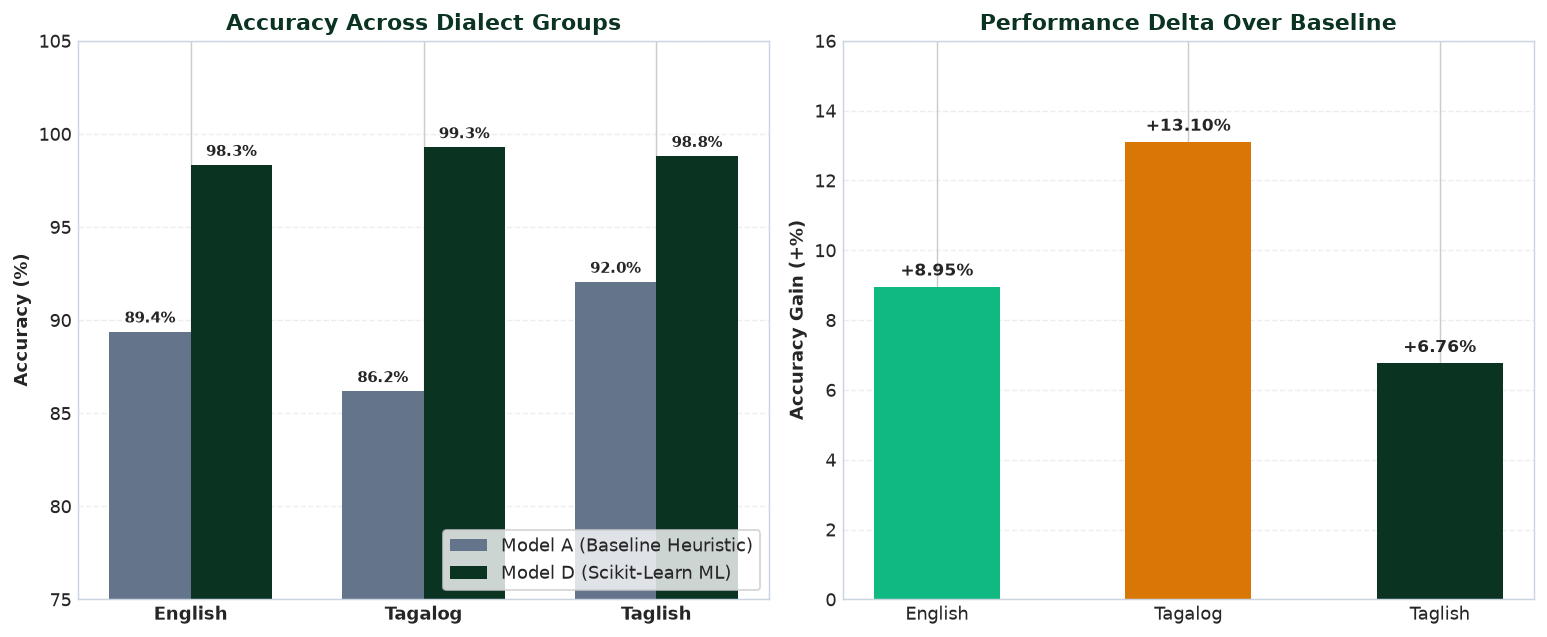

In [5]:
langs = ['English', 'Tagalog', 'Taglish']
x = np.arange(len(langs))
width = 0.35

mod_a = [results['model_a']['per_language'][l]['accuracy'] * 100 for l in langs]
mod_d = [results['model_d']['per_language'][l]['accuracy'] * 100 for l in langs]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=130)

r1 = ax1.bar(x - width/2, mod_a, width, label='Model A (Baseline Heuristic)', color='#64748B')
r2 = ax1.bar(x + width/2, mod_d, width, label='Model D (Scikit-Learn ML)', color='#0B3322')

ax1.set_ylabel('Accuracy (%)', fontsize=10, fontweight='bold')
ax1.set_title('Accuracy Across Dialect Groups', fontsize=12, fontweight='bold', color='#0B3322')
ax1.set_xticks(x)
ax1.set_xticklabels(langs, fontsize=10, fontweight='bold')
ax1.set_ylim(75, 105)
ax1.grid(axis='y', linestyle='--', alpha=0.35)
ax1.legend(loc='lower right', frameon=True, facecolor='white')

for bars in [r1, r2]:
    for bar in bars:
        h = bar.get_height()
        ax1.annotate(f'{h:.1f}%', xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 3),
                     textcoords='offset points', ha='center', va='bottom', fontsize=8.5, fontweight='bold')

gains = [d - a for a, d in zip(mod_a, mod_d)]
r3 = ax2.bar(langs, gains, color=['#10B981', '#D97706', '#0B3322'], width=0.5)
ax2.set_ylabel('Accuracy Gain (+%)', fontsize=10, fontweight='bold')
ax2.set_title('Performance Delta Over Baseline', fontsize=12, fontweight='bold', color='#0B3322')
ax2.set_ylim(0, 16)
ax2.grid(axis='y', linestyle='--', alpha=0.35)

for bar in r3:
    h = bar.get_height()
    ax2.annotate(f'+{h:.2f}%', xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 4),
                 textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()

### 6. Continuous Polarity Distribution ($P \in [-1.0, +1.0]$)
Inspection of continuous polarity scores generated across the 3,000 test partition samples.
Illustrates the bimodal polarity separation with neutral scores tightly bounded within $[-0.05, +0.05]$.

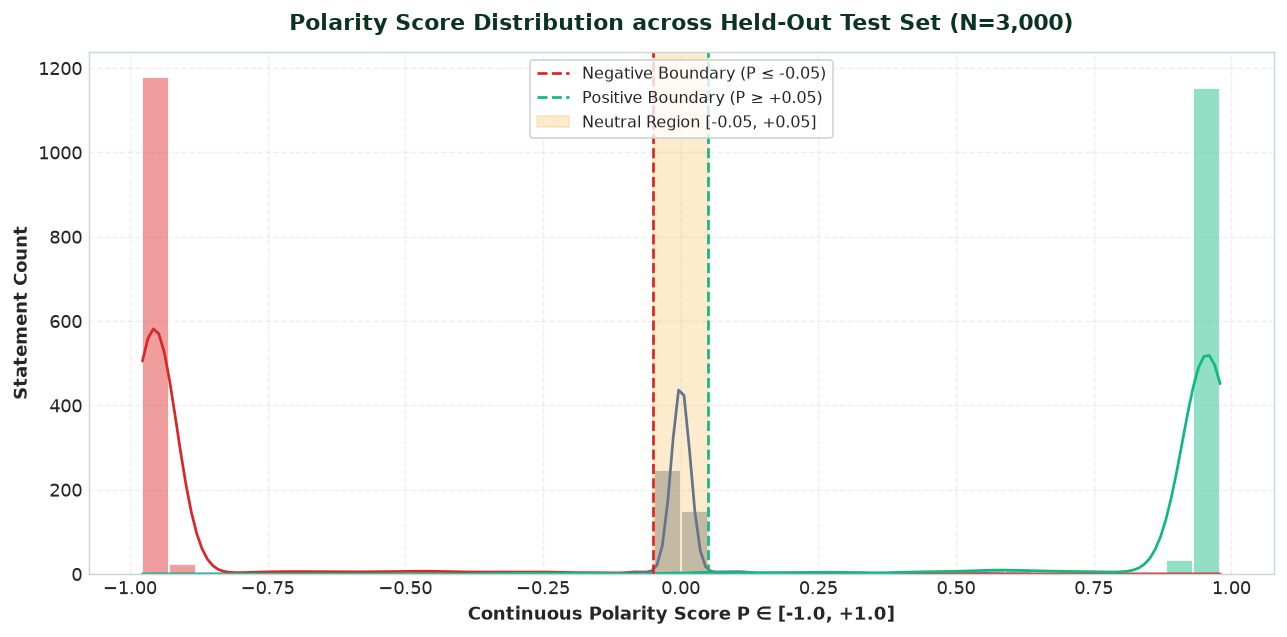

In [6]:
# Compute predictions on test set
test_scores = []
for text in df_test['Feedback_Text']:
    res = ml.classify_text(str(text))
    test_scores.append(res['polarity'])
df_test['pred_polarity'] = test_scores

fig, ax = plt.subplots(figsize=(10, 5), dpi=130)
palette = {'Negative': '#DC2626', 'Neutral': '#64748B', 'Positive': '#10B981'}
sns.histplot(data=df_test, x='pred_polarity', hue='Sentiment', bins=40, kde=True,
             palette=palette, alpha=0.45, edgecolor='white', ax=ax)

ax.axvline(-0.05, color='#DC2626', linestyle='--', lw=1.5, label='Negative Boundary (P ≤ -0.05)')
ax.axvline(0.05, color='#10B981', linestyle='--', lw=1.5, label='Positive Boundary (P ≥ +0.05)')
ax.axvspan(-0.05, 0.05, color='#F59E0B', alpha=0.2, label='Neutral Region [-0.05, +0.05]')

ax.set_xlabel('Continuous Polarity Score P ∈ [-1.0, +1.0]', fontsize=10, fontweight='bold')
ax.set_ylabel('Statement Count', fontsize=10, fontweight='bold')
ax.set_title('Polarity Score Distribution across Held-Out Test Set (N=3,000)', fontsize=12, fontweight='bold', color='#0B3322', pad=12)
ax.grid(True, linestyle='--', alpha=0.3)
ax.legend(loc='upper center', frameon=True, facecolor='white', fontsize=9)
plt.tight_layout()
plt.show()

### 7. 5-Domain Likert Topic Classification
Distribution across the five core pedagogical clusters plus campus facilities isolation.

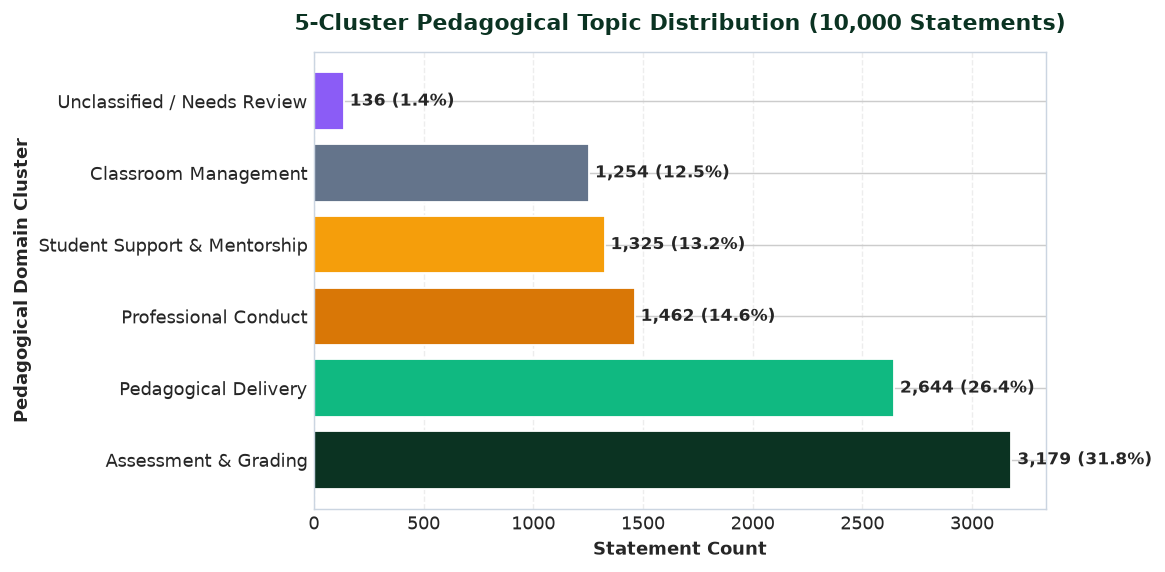

In [7]:
df_all['Likert_Cluster'] = df_all['Aspect'].map(ASPECT_TO_CLUSTER).fillna('Unclassified / Needs Review')
cluster_counts = df_all['Likert_Cluster'].value_counts()
fig, ax = plt.subplots(figsize=(9, 4.5), dpi=130)
colors = ['#0B3322', '#10B981', '#D97706', '#F59E0B', '#64748B', '#8B5CF6']
bars = ax.barh(cluster_counts.index, cluster_counts.values, color=colors[:len(cluster_counts)], edgecolor='white')

ax.set_xlabel('Statement Count', fontsize=10, fontweight='bold')
ax.set_ylabel('Pedagogical Domain Cluster', fontsize=10, fontweight='bold')
ax.set_title('5-Cluster Pedagogical Topic Distribution (10,000 Statements)', fontsize=12, fontweight='bold', color='#0B3322', pad=12)
ax.grid(axis='x', linestyle='--', alpha=0.35)

for bar in bars:
    w = bar.get_width()
    pct = (w / len(df_all)) * 100
    ax.annotate(f' {w:,} ({pct:.1f}%)', xy=(w, bar.get_y() + bar.get_height()/2),
                va='center', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()

### 8. Interactive Live Model Inference Demonstration
Test the production model on sample Filipino, English, and Taglish statements in real-time.

In [8]:
sample_evaluations = [
    'Napakagaling magturo ni Ma\'am, malinaw ang bawat aralin at laging handang tumulong.',
    'Sobrang delayed mag-upload ng grades sa portal tapos laging late pumasok sa klase.',
    'The instructor demonstrates thorough mastery of the syllabus and provides constructive feedback.',
    'Regular class meetings were conducted following the standard course schedule.',
    'Sira yung aircon sa room at maingay sa hallway kaya hirap mag-focus sa discussion.'
]

demo_results = []
for stmt in sample_evaluations:
    res = ml.classify_text(stmt)
    domain = ml.classify_domain(stmt)
    demo_results.append({
        'Evaluation Text': stmt,
        'Predicted Sentiment': res['valence'],
        'Polarity (P)': round(res['polarity'], 4),
        'Pedagogical Domain': domain['cluster'],
        'Domain Confidence': f"{domain['confidence']*100:.1f}%"
    })

demo_table = pd.DataFrame(demo_results)
display(demo_table)

,Evaluation Text,Predicted Sentiment,Polarity (P),Pedagogical Domain,Domain Confidence
0,"Napakagaling magturo ni Ma'am, malinaw ang baw...",Positive,0.7411,Pedagogical Delivery,81.9%
1,Sobrang delayed mag-upload ng grades sa portal...,Negative,-0.6955,Classroom Management,54.0%
2,The instructor demonstrates thorough mastery o...,Positive,0.7304,Pedagogical Delivery,76.4%
3,Regular class meetings were conducted followin...,Neutral,-0.0164,Pedagogical Delivery,32.1%
4,Sira yung aircon sa room at maingay sa hallway...,Negative,-0.2773,Unclassified / Needs Review,36.1%


### 9. Institutional Governance Alignment
- **AACCUP Level III Area III**: Provides objective, reproducible evaluation analytics backed by held-out statistical evidence.
- **Zero Permits Policy**: Operates with complete decoupling from student examination clearance.
- **Cryptographic Student Anonymity**: Evaluative qualitative sentiments are securely processed through salted hash verification without recording PII or student keys into the analytics vault.